In [1]:
import pandas as pd

Loading dataset

In [2]:
df=pd.read_csv("spam.csv",encoding="latin-1")

checking the dataset

In [3]:
df.shape

(5572, 5)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [5]:
df.describe()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
count,5572,5572,50,12,6
unique,2,5169,43,10,5
top,ham,"Sorry, I'll call later","bt not his girlfrnd... G o o d n i g h t . . .@""","MK17 92H. 450Ppw 16""","GNT:-)"""
freq,4825,30,3,2,2


In [6]:
df.isnull().sum()

v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

In [7]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [8]:
df.columns

Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')

In [9]:
import numpy as np

In [10]:
import matplotlib as plt

In [11]:
import seaborn as sn

In [12]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


Remove other unnecessary columns

In [13]:
df=df[['v1','v2']]
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Rename them as Label and Message

In [45]:
df.rename(columns={
    'v1':'label',
    'v2':'message'
})

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [44]:
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


basic EDA

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5169 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5169 non-null   object
 1   message  5169 non-null   object
dtypes: object(2)
memory usage: 121.1+ KB


In [47]:
df.shape

(5169, 2)

In [48]:
df.isnull().sum()

label      0
message    0
dtype: int64

In [49]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
5567    False
5568    False
5569    False
5570    False
5571    False
Length: 5169, dtype: bool

In [20]:
df = df.drop_duplicates()

### Removing Duplicate Rows

Duplicate rows were checked using `df.duplicated().sum()`. Duplicate messages can introduce repeated examples into the dataset and may bias model evaluation. Therefore, duplicate rows were removed using `df.drop_duplicates()` to keep only unique records.

In [43]:
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [50]:
df['label'].value_counts()

label
ham     4516
spam     653
Name: count, dtype: int64

In [51]:
df['label'].value_counts(normalize=True)*100

label
ham     87.366996
spam    12.633004
Name: proportion, dtype: float64

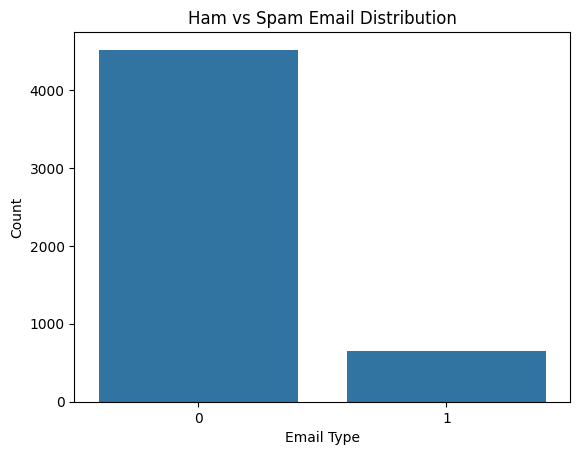

In [83]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(data=df, x='label')

plt.title('Ham vs Spam Email Distribution')
plt.xlabel('Email Type')
plt.ylabel('Count')
plt.show()

### Class Distribution

The dataset contains ham emails 87.36% and 12.63% spam emails. Ham emails make up the majority of the dataset, while spam emails represent a smaller proportion. Therefore, the dataset has an imbalanced class distribution. Accuracy alone can be misleading because a model could predict the majority class most of the time while failing to detect spam emails.

In [52]:
df['label'].value_counts(normalize=True)*100


label
ham     87.366996
spam    12.633004
Name: proportion, dtype: float64

In [ ]:
print(df.columns.tolist())

['label', 'message']


In [63]:
df = df.rename(columns={'v1': 'label', 'v2': 'message'})

In [64]:
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Mapping 0 and 1 to 'ham and 'spam' respectively

In [65]:
df['label']=df['label'].map({
    'ham':0,
    'spam':1
    
})

In [66]:
df.head()

,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [68]:
df.head()

,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [79]:
df['message_length'] = df['message'].str.len()

In [80]:
df.head()

,label,message,message_length
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [81]:
df.groupby('label')['message_length'].mean()

label
0     70.459256
1    137.891271
Name: message_length, dtype: float64

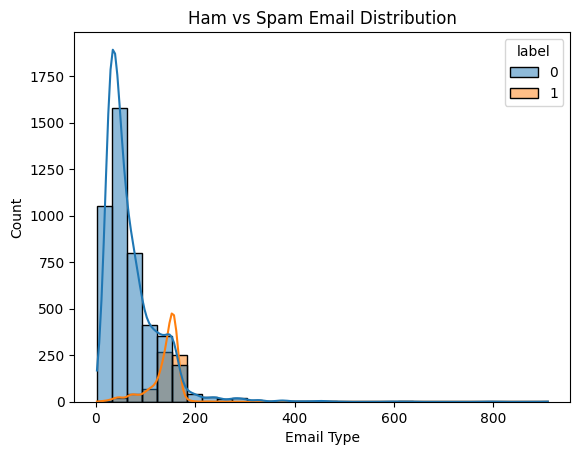

In [85]:
sns.histplot(
    data=df,
    x='message_length',
    hue='label',
    bins=30,
    kde=True
)

plt.title('Ham vs Spam Email Distribution')
plt.xlabel('Email Type')
plt.ylabel('Count')
plt.show()


**spam messages are usually longer**

In [89]:
df['message']=df['message'].str.lower()

In [90]:
df.head()

,label,message,message_length
0,0,"go until jurong point, crazy.. available only ...",111
1,0,ok lar... joking wif u oni...,29
2,1,free entry in 2 a wkly comp to win fa cup fina...,155
3,0,u dun say so early hor... u c already then say...,49
4,0,"nah i don't think he goes to usf, he lives aro...",61


TEXT PREPROCESSING

In [91]:
import re

In [101]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()
    words = [w for w in words if w not in stop_words]
    words = [stemmer.stem(w) for w in words]
    return ' '.join(words)

df['clean_message'] = df['message'].apply(clean_text)
df[['message', 'clean_message']].head()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ACER\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


,message,clean_message
0,"go until jurong point, crazy.. available only ...",go jurong point crazi avail bugi n great world...
1,ok lar... joking wif u oni...,ok lar joke wif u oni
2,free entry in 2 a wkly comp to win fa cup fina...,free entri wkli comp win fa cup final tkt st m...
3,u dun say so early hor... u c already then say...,u dun say earli hor u c alreadi say
4,"nah i don't think he goes to usf, he lives aro...",nah dont think goe usf live around though


building model and fit 

In [111]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df['clean_message'],
    df['label'],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

In [113]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=3000)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

TF-IDF stands for **Term Frequency–Inverse Document Frequency**. It converts text messages into numerical features that a machine learning model can use.

- **Term Frequency (TF):** Measures how often a word appears in a particular message. A word that appears more frequently in a message may receive a higher term-frequency value.
- **Inverse Document Frequency (IDF):** Measures how common or rare a word is across all messages. Words appearing in many messages receive lower IDF weights, while rarer words receive higher weights.
- **TF-IDF together:** Combines these two ideas. Words that appear frequently in a particular message but are uncommon across the overall collection tend to receive higher scores.

In this spam detection project, TF-IDF helps represent the words in each message numerically so a machine learning model can learn patterns associated with spam and ham messages.

In [114]:
print("Training data:", X_train_tfidf.shape)
print("Testing data:", X_test_tfidf.shape)

Training data: (4135, 3000)
Testing data: (1034, 3000)


**Train model**

In [115]:
from sklearn.naive_bayes import MultinomialNB

In [117]:
model = MultinomialNB()
model.fit(X_train_tfidf,y_train)
y_predict=model.predict(X_test_tfidf)

In [125]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Calculate accuracy
print("Accuracy:", accuracy_score(y_test, y_predict))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_predict))

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_predict,
    target_names=["Ham", "Spam"]
))

Accuracy: 0.9709864603481625

Confusion Matrix:
[[902   1]
 [ 29 102]]

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       903
        Spam       0.99      0.78      0.87       131

    accuracy                           0.97      1034
   macro avg       0.98      0.89      0.93      1034
weighted avg       0.97      0.97      0.97      1034



**Trained model on Naives Bayes, Now its time for another model  its logisitic regression**

In [137]:
from sklearn.linear_model import LogisticRegression
LR_model= LogisticRegression(max_iter=1000)
LR_model.fit(X_train_tfidf,y_train)
LR_predict=LR_model.predict(X_test_tfidf)


In [145]:

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Accuracy:", accuracy_score(y_test, LR_predict))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, LR_predict))

print("\nClassification Report:")
print(classification_report(
    y_test,
    LR_predict,
    target_names=["Ham", "Spam"]
))


Accuracy: 0.9642166344294004

Confusion Matrix:
[[903   0]
 [ 37  94]]

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.72      0.84       131

    accuracy                           0.96      1034
   macro avg       0.98      0.86      0.91      1034
weighted avg       0.97      0.96      0.96      1034



Compare the models

In [147]:
from sklearn.metrics import classification_report

print("Naive Bayes Results")
print(classification_report(
    y_test, y_predict,
    target_names=["Ham", "Spam"]
))

print("Logistic Regression Results")
print(classification_report(
    y_test, LR_predict,
    target_names=["Ham", "Spam"]
))

Naive Bayes Results
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       903
        Spam       0.99      0.78      0.87       131

    accuracy                           0.97      1034
   macro avg       0.98      0.89      0.93      1034
weighted avg       0.97      0.97      0.97      1034

Logistic Regression Results
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.72      0.84       131

    accuracy                           0.96      1034
   macro avg       0.98      0.86      0.91      1034
weighted avg       0.97      0.96      0.96      1034



In [148]:
df.head()

,label,message,message_length,clean_message
0,0,"go until jurong point, crazy.. available only ...",111,go jurong point crazi avail bugi n great world...
1,0,ok lar... joking wif u oni...,29,ok lar joke wif u oni
2,1,free entry in 2 a wkly comp to win fa cup fina...,155,free entri wkli comp win fa cup final tkt st m...
3,0,u dun say so early hor... u c already then say...,49,u dun say earli hor u c alreadi say
4,0,"nah i don't think he goes to usf, he lives aro...",61,nah dont think goe usf live around though


**SPAM DETECTION**

In [150]:
print(model)

<class 'sklearn.linear_model._logistic.LogisticRegression'>


In [151]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [152]:
messages = [
    "Hey, are we meeting for lunch today?",
    "Congratulations! You have won a free prize. Click here now!",
    "URGENT! Claim your cash reward now!"
]

cleaned_messages = [clean_text(msg) for msg in messages]

message_vectors = vectorizer.transform(cleaned_messages)

predictions = model.predict(message_vectors)

for message, prediction in zip(messages, predictions):
    label = "Spam" if prediction == 1 else "Ham"
    print(f"Message: {message}")
    print(f"Prediction: {label}\n")

Message: Hey, are we meeting for lunch today?
Prediction: Ham

Message: Congratulations! You have won a free prize. Click here now!
Prediction: Spam

Message: URGENT! Claim your cash reward now!
Prediction: Spam



**Now Save both the model**

In [154]:

import pickle

# Save the Naive Bayes model
with open("naive_bayes_model.pkl", "wb") as file:
    pickle.dump(model, file)

# Save the Logistic Regression model
with open("logistic_regression_model.pkl", "wb") as file:
    pickle.dump(LR_model, file)

# Save the TF-IDF vectorizer
with open("tfidf_vectorizer.pkl", "wb") as file:
    pickle.dump(vectorizer, file)

print("Both models and the TF-IDF vectorizer saved successfully!")


Both models and the TF-IDF vectorizer saved successfully!


## Conclusion

In this project, I developed an SMS Spam Detection system using machine learning. I cleaned and preprocessed the text messages, removed duplicate records, and converted text into numerical features using TF-IDF vectorization.

I trained and evaluated two machine learning models: Multinomial Naive Bayes and Logistic Regression. I compared their performance using accuracy, precision, recall, F1-score, and confusion matrices.

Naive Bayes achieved higher recall for the spam class in my evaluation, meaning it identified a greater proportion of actual spam messages than Logistic Regression. I also tested the trained model on new messages and saved both trained models and the TF-IDF vectorizer for future use.

This project helped me understand the complete machine learning workflow, from data preprocessing and model training to evaluation, prediction, and model saving.